# 02. Exploratory Data Analysis (EDA)

## Objective
Visualize variable distributions, evaluate normality assumptions, and examine bivariate patterns between social media habits and mental wellbeing indicators prior to formal hypothesis testing.


In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set clean, publication-ready plot style
sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams['figure.dpi'] = 120

# Paths
DATA_PATH = '../data/processed/cleaned_wellbeing_data.csv'
FIGURES_DIR = '../reports/figures/'
os.makedirs(FIGURES_DIR, exist_ok=True)


### Step 1: Load Processed Data & Descriptive Summary
Load `cleaned_wellbeing_data.csv` and inspect central tendency, spread, and quartiles across all numeric variables.


In [11]:
df = pd.read_csv(DATA_PATH)

SCREEN_COL = 'daily_screen_time'
WELLBEING_COL = 'mental_distress_score'  # Or test 'depression_score' / 'sleep_issues_score'
GROUP_COL = 'usage_tier'

print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns.")
display(df.describe().T)


Loaded 481 rows and 25 columns.


,count,mean,std,min,25%,50%,75%,max
age,481.0,26.136590,9.915110,13.0,21.0,22.0,26.0,91.0
purposeless_use,481.0,3.553015,1.096299,1.0,3.0,4.0,4.0,5.0
distracted_busy,481.0,3.320166,1.328137,1.0,2.0,3.0,4.0,5.0
restlessness,481.0,2.588358,1.257059,1.0,2.0,2.0,3.0,5.0
easily_distracted,481.0,3.349272,1.175552,1.0,3.0,3.0,4.0,5.0
worries_score,481.0,3.559252,1.283356,1.0,3.0,4.0,5.0,5.0
concentration_diff,481.0,3.245322,1.347105,1.0,2.0,3.0,4.0,5.0
social_comparison,481.0,2.831601,1.407835,1.0,2.0,3.0,4.0,5.0
comparison_feeling,481.0,2.775468,1.056479,1.0,2.0,3.0,3.0,5.0
validation_seeking,481.0,2.455301,1.247739,1.0,1.0,2.0,3.0,5.0


### Step 2: Normality & Distribution Diagnostics (`01_distributions_qq.png`)
* **Observation:** `daily_screen_time` exhibits discrete step-like clustering across the six survey intervals, with the largest respondent group in the `>5 hours` bracket (`5.5h`).
* **Normality Check:** Both Q-Q plots deviate from the theoretical normal reference line at the tails, confirming that non-parametric rank-based tests (Spearman's $\rho$, Kruskal-Wallis) are appropriate.


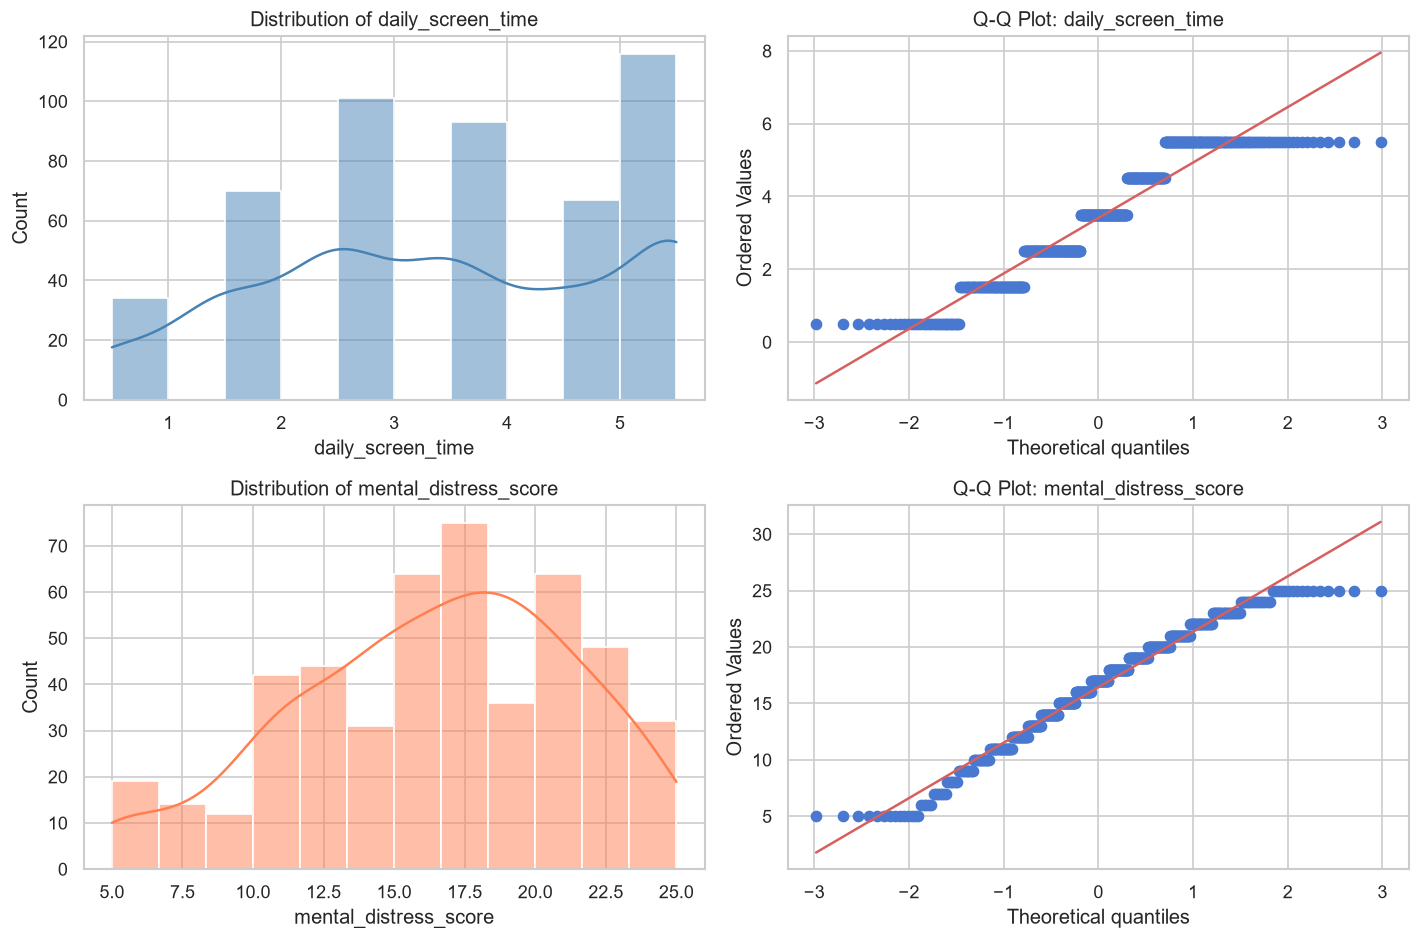

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Screen Time Histogram + KDE
sns.histplot(df[SCREEN_COL], kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title(f'Distribution of {SCREEN_COL}')

# 2. Screen Time Q-Q Plot
stats.probplot(df[SCREEN_COL].dropna(), dist="norm", plot=axes[0, 1])
axes[0, 1].set_title(f'Q-Q Plot: {SCREEN_COL}')

# 3. Wellbeing Score Histogram + KDE
sns.histplot(df[WELLBEING_COL], kde=True, ax=axes[1, 0], color='coral')
axes[1, 0].set_title(f'Distribution of {WELLBEING_COL}')

# 4. Wellbeing Score Q-Q Plot
stats.probplot(df[WELLBEING_COL].dropna(), dist="norm", plot=axes[1, 1])
axes[1, 1].set_title(f'Q-Q Plot: {WELLBEING_COL}')

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}01_distributions_qq.png", bbox_inches='tight')
plt.show()


### Step 3: Spearman Rank Correlation Matrix (`02_correlation_heatmap.png`)
* **Key Takeaway:** Strong positive inter-correlations appear among cognitive distraction and emotional distress items—most notably between `easily_distracted` and `concentration_diff` ($\rho = 0.67$), `easily_distracted` and `distracted_busy` ($\rho = 0.60$), and `worries_score` and `depression_score` ($\rho = 0.58$).
* **Age Effect:** `age` correlates negatively with nearly all digital distraction and distress indicators (e.g., $\rho = -0.26$ with `interest_fluctuation`, $\rho = -0.24$ with `worries_score`).


C:\Users\ASUS\AppData\Local\Temp\ipykernel_19296\585364608.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


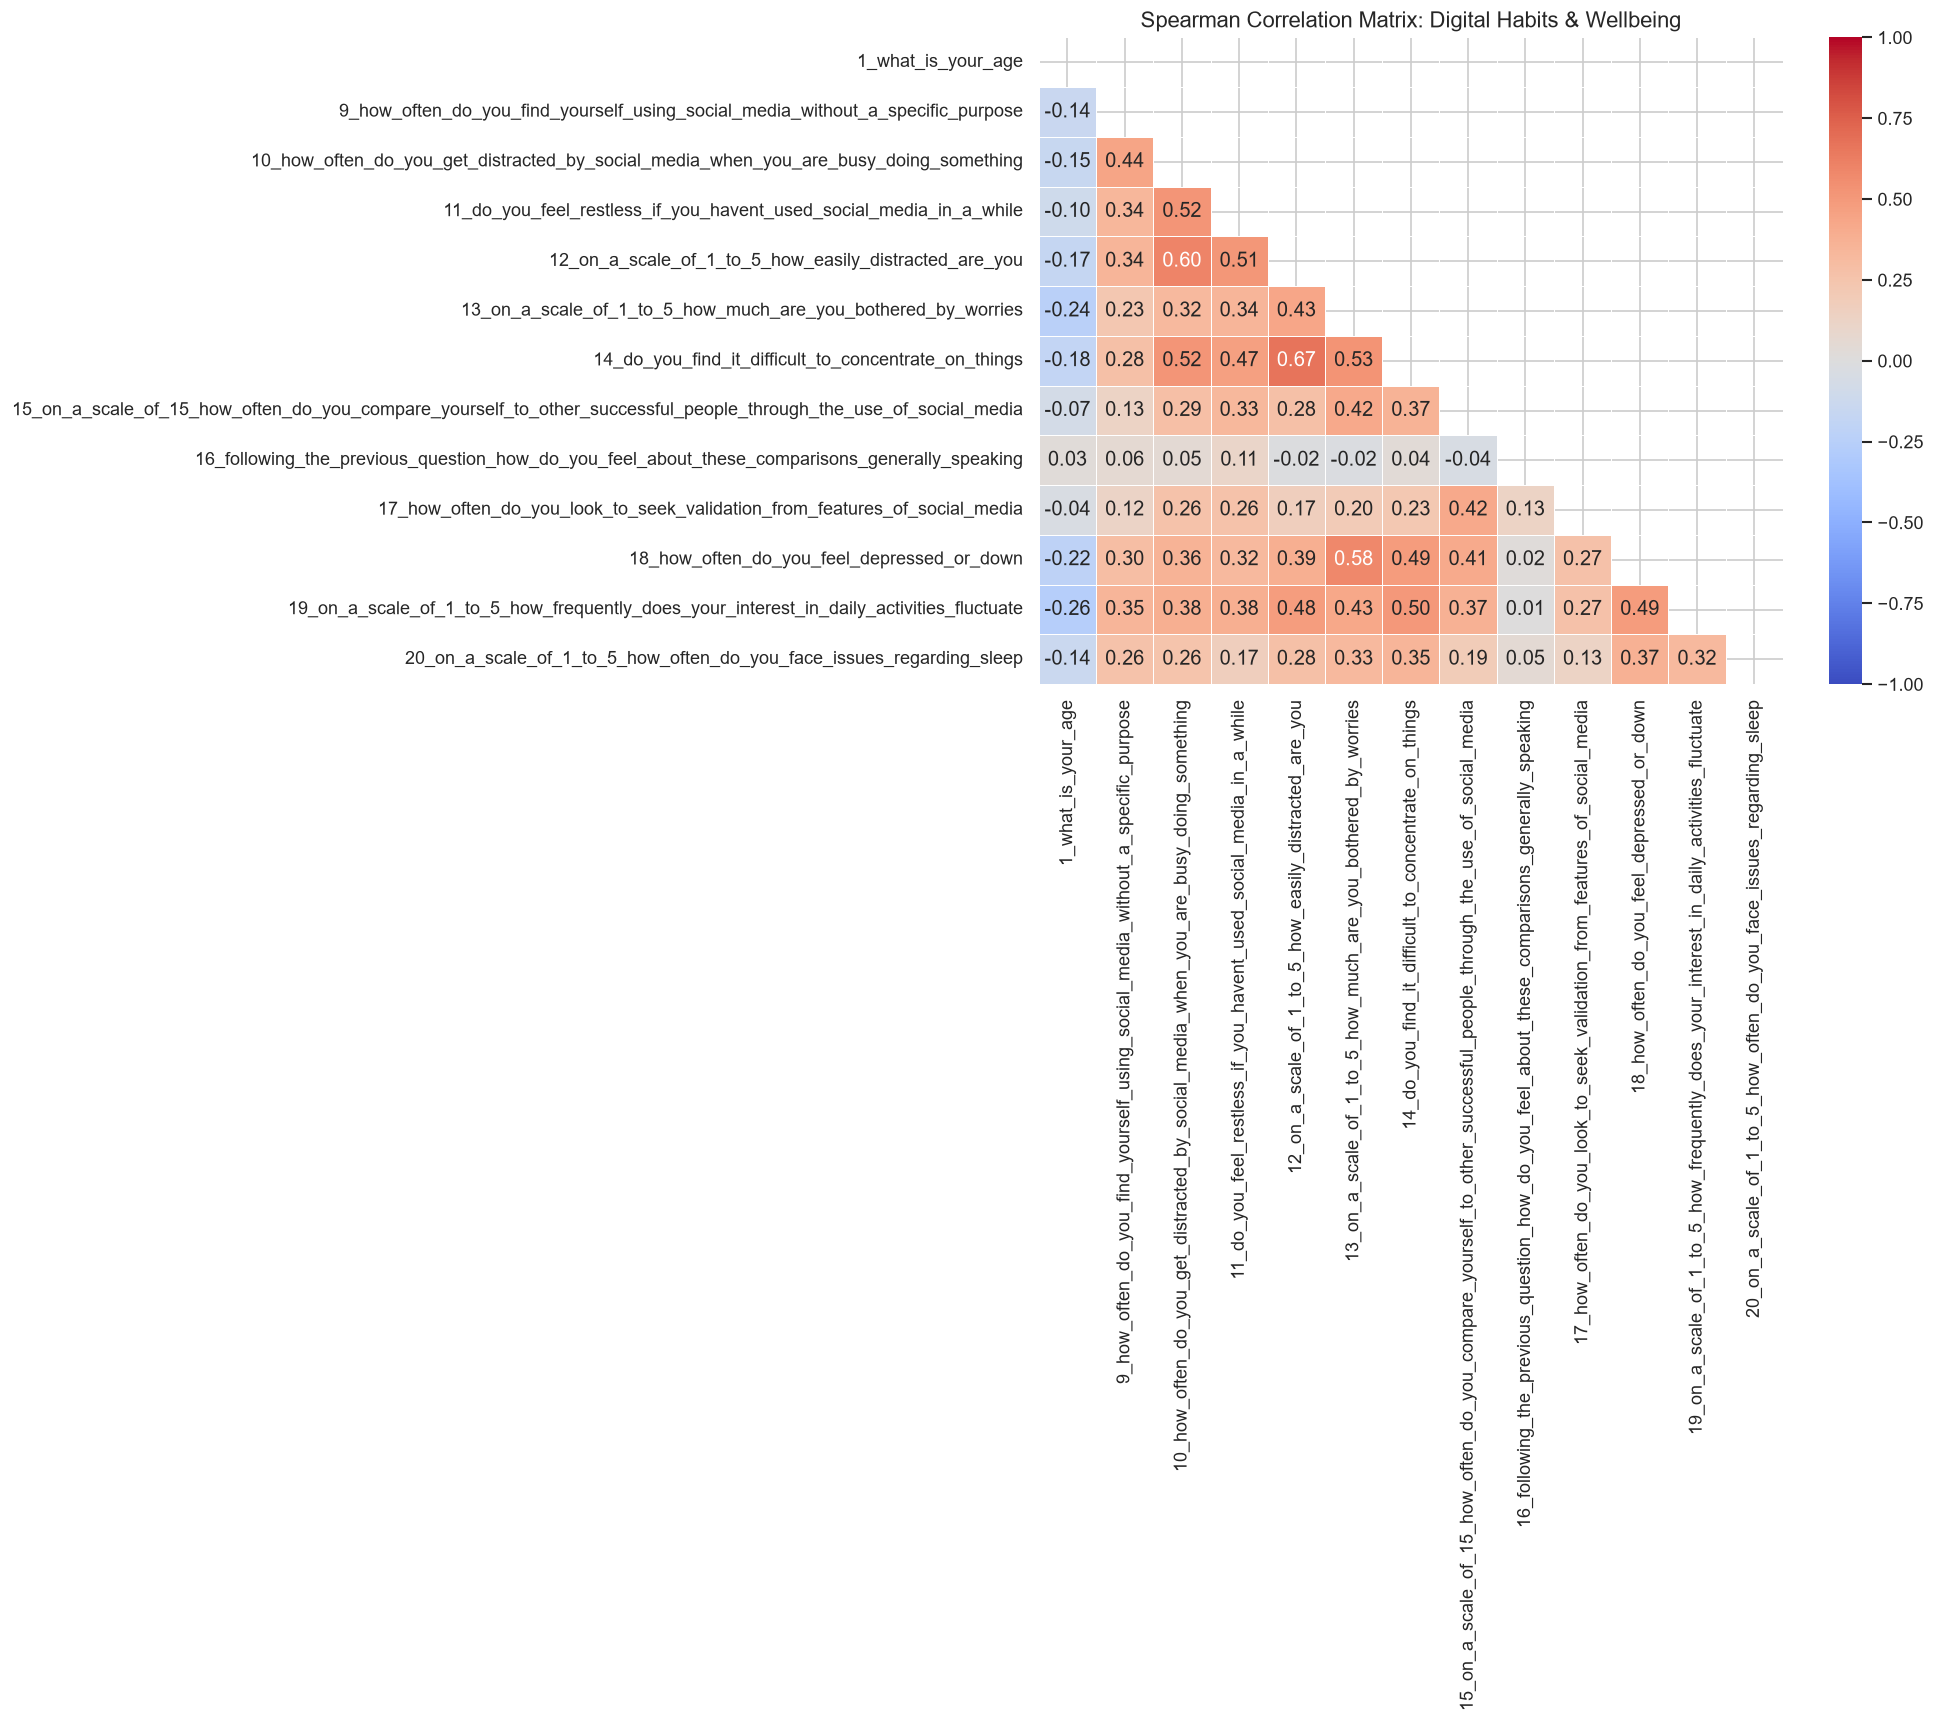

In [4]:
num_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 7))
corr_matrix = num_df.corr(method='spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Hide upper triangle

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.5
)
plt.title("Spearman Correlation Matrix: Digital Habits & Wellbeing", fontsize=13)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}02_correlation_heatmap.png", bbox_inches='tight')
plt.show()


### Step 4: Mental Distress Across Digital Usage Tiers (`03_wellbeing_by_usage_tier.png`)
* **Key Takeaway:** Median `mental_distress_score` rises steadily across usage tiers:
  * **Low (<2h):** Median = **13.0** (IQR: 9.0–17.0)
  * **Moderate (2–5h):** Median = **18.0** (IQR: 14.0–20.0)
  * **High (>5h):** Median = **19.0** (IQR: 16.0–22.0)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_19296\464307503.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


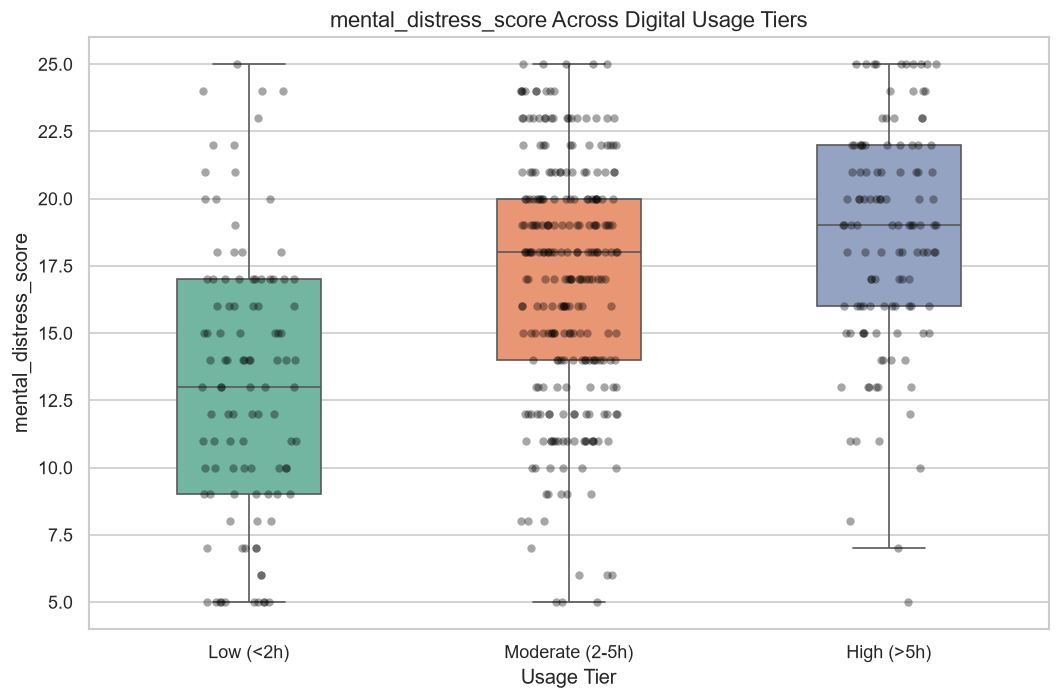

In [13]:
if GROUP_COL in df.columns:
    plt.figure(figsize=(9, 6))
    
    # Ensure logical order if using the tiers from Notebook 1
    tier_order = ['Low (<2h)', 'Moderate (2-5h)', 'High (>5h)']
    order = [t for t in tier_order if t in df[GROUP_COL].unique()] or None

    sns.boxplot(
        data=df,
        x=GROUP_COL,
        y=WELLBEING_COL,
        order=order,
        width=0.45,
        fliersize=0,
        palette='Set2'
    )
    sns.stripplot(
        data=df,
        x=GROUP_COL,
        y=WELLBEING_COL,
        order=order,
        color='black',
        alpha=0.35,
        jitter=0.15
    )
    
    plt.title(f'{WELLBEING_COL} Across Digital Usage Tiers', fontsize=13)
    plt.xlabel('Usage Tier')
    plt.ylabel(WELLBEING_COL)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}03_wellbeing_by_usage_tier.png", bbox_inches='tight')
    plt.show()


### Step 5: Bivariate Linear Trend (`04_regression_trend.png`)
* **Key Takeaway:** Simple linear regression shows a clear upward slope with a tight 95% confidence band, rising from a predicted mean distress score of **~13.0** at `0.5h/day` to **~19.0** at `5.5h/day`.


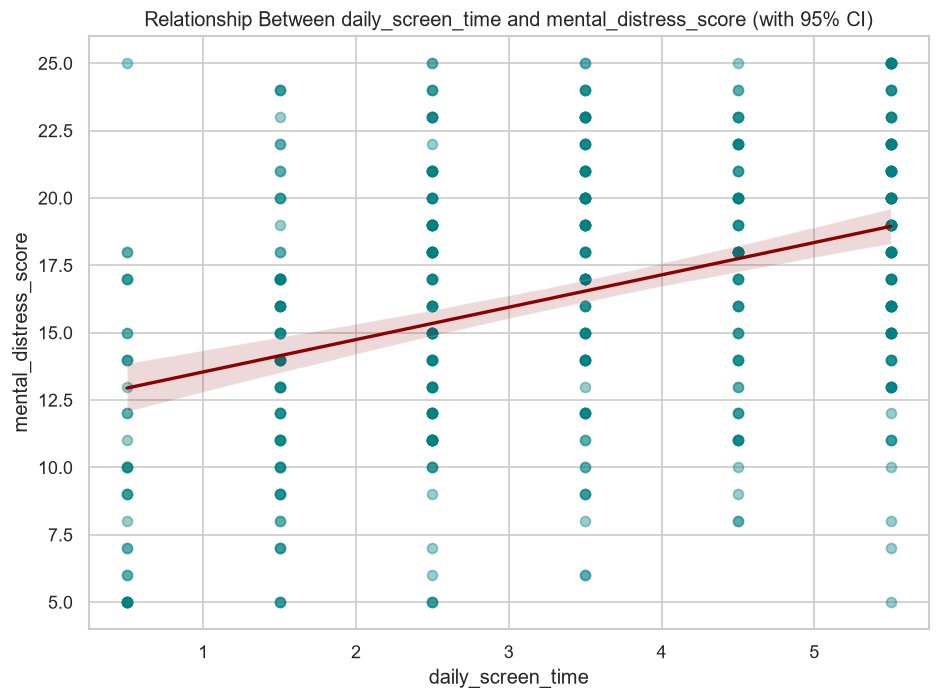

In [14]:
plt.figure(figsize=(8, 6))
sns.regplot(
    data=df,
    x=SCREEN_COL,
    y=WELLBEING_COL,
    scatter_kws={'alpha': 0.4, 'color': 'teal'},
    line_kws={'color': 'darkred', 'linewidth': 2}
)
plt.title(f'Relationship Between {SCREEN_COL} and {WELLBEING_COL} (with 95% CI)', fontsize=12)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}04_regression_trend.png", bbox_inches='tight')
plt.show()


### Step 6: Tier Summary Statistics Table
Generate exact sample counts, means, standard deviations, medians, and interquartile ranges (IQR) across each usage tier for reporting.


In [15]:
if GROUP_COL in df.columns:
    summary_table = df.groupby(GROUP_COL)[WELLBEING_COL].agg(
        count='count',
        mean='mean',
        std='std',
        median='median',
        iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)
    ).round(2)
    
    print("--- Group Summary Table ---")
    display(summary_table)


--- Group Summary Table ---


,count,mean,std,median,iqr
usage_tier,,,,,
High (>5h),116,18.47,4.20,19.0,6.0
Low (<2h),104,13.12,5.08,13.0,8.0
Moderate (2-5h),261,16.85,4.57,18.0,6.0
